# 05. Criminisi: inpainting basado en ejemplares

Este cuaderno explica y prueba el método de **Criminisi, Pérez y Toyama**, «Region Filling and Object Removal by Exemplar-Based Image Inpainting», *IEEE Transactions on Image Processing*, 13(9), 2004, pp. 1200–1212. En el código lo llamamos **[1]**. Referencia: [PDF original de Microsoft Research](https://www.microsoft.com/en-us/research/wp-content/uploads/2016/02/criminisi_tip2004.pdf).

En los cuadernos 03 y 04 hemos restaurado mediante difusión; aquí no calculamos medias dentro del hueco: **elegimos un parche del borde, buscamos uno similar en la región conocida original y copiamos los píxeles que faltan**. La prioridad del borde favorece la información fiable y la prolongación de estructuras. Véase [1, sección III, ecuaciones (1)-(2) y tabla I, pp. 4-5 del PDF].

Para ver el funcionamiento, este cuaderno enseña las partes del algoritmo, las verifica con ejemplos pequeños y después muestra una reconstrucción completa. El código está en `src/ejemplares.py`; el cuaderno **no duplica** la implementación. Mantiene las mismas convenciones que los notebooks de Juanlu: imagen RGB o gris, posiciones `(fila, columna)` y máscara booleana (`True` = hueco).

**Enfoque:** la prioridad y la búsqueda se basan en [1], pero la estimación discreta de gradientes y normales y el desempate se han concretado en nuestra implementación y se señalan al final. No afirmamos que sea idéntico, píxel a píxel, al ejecutable de los autores.

In [1]:
from pathlib import Path
import sys
import time

import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# Funciona si VS Code ejecuta el notebook desde notebooks/ O desde la raíz.
raiz = Path.cwd().resolve()
if not (raiz / "src").is_dir():
    raiz = raiz.parent
if not (raiz / "src").is_dir():
    raise FileNotFoundError("Abre este notebook desde la carpeta raíz del repositorio o desde notebooks/.")
sys.path.insert(0, str(raiz / "src"))

import mascaras as m
import metricas as k
import ejemplares as e

print("Raíz del proyecto:", raiz)
print("NumPy", np.__version__, "| OpenCV", cv.__version__)

Raíz del proyecto: /Users/juanlu/Desktop/Universidad/4º/PID/inpainting-difusion-ejemplares
NumPy 2.4.6 | OpenCV 5.0.0


## 1. El problema: imagen, máscara, región fuente y parches

Llamamos $\Omega$ al conjunto de píxeles desconocidos (`mascara == True`). La **región fuente $\Phi$ permanece fija** y contiene los píxeles conocidos desde el principio; un parche que incluya siquiera un píxel del hueco original no se usa como parche fuente. Los píxeles recién rellenados, en cambio, sí cuentan como conocidos para comparar las posiciones visibles del siguiente parche objetivo [1, secciones II.A y III].

Para empezar creamos una imagen sintética de dos materiales con un borde vertical. Así sabemos cuál debería ser el resultado y podemos medir el error. La zona blanca de la imagen dañada **no es una pista del algoritmo**: los píxeles blancos del hueco se ignoran mediante la máscara.

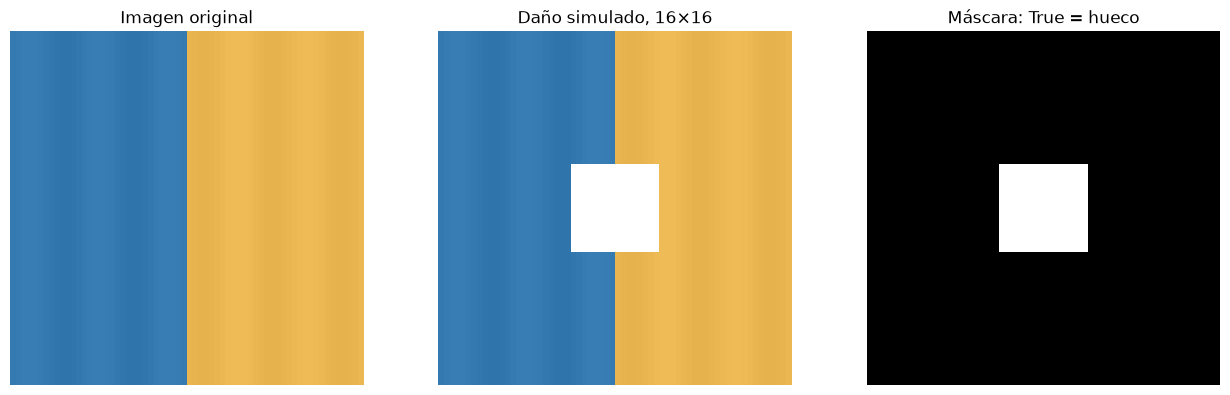

Píxeles desconocidos: 256


In [2]:
N = 64
original = np.empty((N, N, 3), dtype=np.uint8)
original[:, :N//2] = [52, 121, 176]
original[:, N//2:] = [235, 183, 83]
# Textura suave repetida: añade información que el método debe copiar.
filas, columnas = np.indices((N, N))
original = np.clip(original.astype(np.int16) + (5 * np.sin(columnas/2.0))[...,None], 0, 255).astype(np.uint8)
mascara = m.mascara_cuadrada(original.shape[:2], lado=16)
danada = m.aplicar_mascara(original, mascara)
tam_parche = 7

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
axes[0].imshow(original); axes[0].set_title("Imagen original")
axes[1].imshow(danada); axes[1].set_title("Daño simulado, 16×16")
axes[2].imshow(mascara, cmap="gray"); axes[2].set_title("Máscara: True = hueco")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()
print("Píxeles desconocidos:", int(mascara.sum()))

## 2. La frontera $\partial\Omega$ y la confianza $C(p)$

La frontera de relleno se actualiza en cada iteración. Aquí la representamos como los **píxeles desconocidos que tienen algún vecino conocido de arriba, abajo, izquierda o derecha**. Es una definición discreta de la frontera; el artículo habla de un contorno continuo [1, sección III].

Inicialmente $C(q)=1$ para conocidos y $C(q)=0$ para desconocidos. Para un parche $\Psi_p$ centrado en $p$:

$$ C(p)=\frac{\sum_{q\in\Psi_p\cap(I-\Omega)} C(q)}{|\Psi_p|}. $$

Cuando se copia un parche, **solo los píxeles nuevos** reciben la confianza $C(p)$; no se recalcula la confianza de los anteriores [1, sección III, paso 3].

### Prueba calculable a mano

En una máscara de $7\times7$ con hueco central $3\times3$, el parche $3\times3$ centrado en la esquina superior izquierda del hueco contiene **5 píxeles conocidos de 9**. Por tanto su confianza debe ser $5/9$.

Confianza C(2,2): 0.555556 = 5/9
Píxeles de frontera: 8


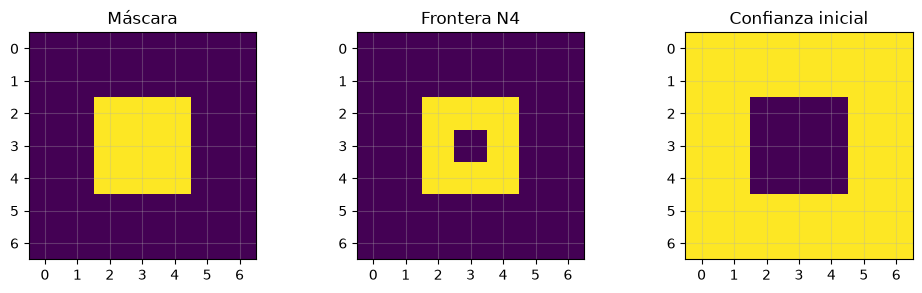

In [3]:
mascara_test = np.zeros((7, 7), dtype=bool)
mascara_test[2:5, 2:5] = True
frontera_test = e.obtener_borde(mascara_test)
C_inicial = e.confianza_inicial(mascara_test)
C_mano = e.calcular_confianza((2, 2), C_inicial, mascara_test, tam_parche=3)
assert np.isclose(C_mano, 5/9)
assert frontera_test.sum() == 8   # centro de 3x3 no toca conocidos N4

print(f"Confianza C(2,2): {C_mano:.6f} = 5/9")
print("Píxeles de frontera:", int(frontera_test.sum()))
fig, axes = plt.subplots(1, 3, figsize=(10, 3))
for ax, im, titulo in zip(axes, (mascara_test, frontera_test, C_inicial),
                         ("Máscara", "Frontera N4", "Confianza inicial")):
    ax.imshow(im, cmap="viridis", vmin=0, vmax=1)
    ax.set_title(titulo); ax.set_xticks(range(7)); ax.set_yticks(range(7)); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 3. Dirección de las isófotas y término de datos $D(p)$

La confianza por sí sola tendería a rellenar el hueco por capas. Criminisi añade un término que da prioridad a los lugares donde una **estructura entra al hueco** [1, sección III, figura 5]:

$$ D(p)=\frac{|\nabla I_p^{\perp}\cdot\mathbf n_p|}{\alpha},\qquad \alpha=255. $$

- $\nabla I_p$ es el gradiente de mayor módulo obtenido entre los píxeles conocidos del parche.
- $\nabla I_p^{\perp}$ es su rotación $90^\circ$, la dirección de la **isófota**.
- $\mathbf n_p$ es la normal al contorno del hueco en $p$.
- La magnitud del producto escalar aumenta cuando la isófota apunta hacia el interior del hueco.

**Cuidado con las coordenadas:** en NumPy el primer eje son las filas y el segundo las columnas. Mantenemos el mismo orden `(fila, columna)` en gradientes, normales e isófotas.

Nuestra implementación aproxima la normal con el gradiente de la máscara suavizada (filtro binomial 3×3), y estima gradientes sin usar píxeles que aún están vacíos. Son decisiones de discretización propias, no ecuaciones adicionales del artículo.

Parche objetivo (fila, columna): (24, 29)
C = 0.4286 | D = 0.1481 | P = 0.0635 (comprobación: 0.0635)


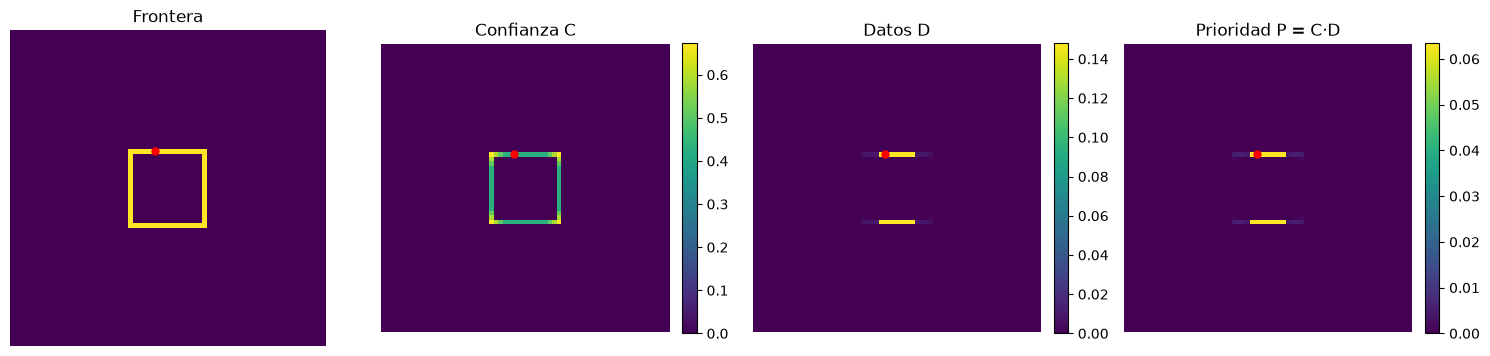

In [4]:
confianza = e.confianza_inicial(mascara)
borde, mapa_C, mapa_D, mapa_P = e.calcular_prioridades(danada, mascara, confianza, tam_parche)
assert np.array_equal(borde, e.obtener_borde(mascara))
assert np.allclose(mapa_P, mapa_C * mapa_D)
assert np.all(mapa_P[~borde] == 0)

# En caso de empate, se elige primero la mayor confianza y después orden de lectura.
candidatos = [(mapa_P[f,c], mapa_C[f,c], (int(f),int(c)), mapa_D[f,c]) for f,c in np.argwhere(borde)]
P, C, elegido, D = max(candidatos, key=lambda x: (x[0],x[1],-x[2][0],-x[2][1]))
print("Parche objetivo (fila, columna):", elegido)
print(f"C = {C:.4f} | D = {D:.4f} | P = {P:.4f} (comprobación: {C*D:.4f})")

fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, data, titulo in zip(axes,
                           (borde, mapa_C, mapa_D, mapa_P),
                           ("Frontera", "Confianza C", "Datos D", "Prioridad P = C·D")):
    im = ax.imshow(data, cmap="viridis")
    ax.set_title(titulo); ax.scatter([elegido[1]], [elegido[0]], c="red", s=25)
    ax.axis("off")
    if titulo != "Frontera": fig.colorbar(im, ax=ax, fraction=.046, pad=.04)
plt.tight_layout(); plt.show()

## 4. Del parche objetivo al parche fuente: búsqueda por SSD

Una vez elegido el parche objetivo $\Psi_{\hat p}$, el algoritmo busca un parche **completamente contenido en la región fuente ORIGINAL** que minimice la suma de diferencias al cuadrado (SSD) sobre las posiciones conocidas del objetivo [1, sección III, ecuación (2)]:

$$\Psi_{\hat q}=\arg\min_{\Psi_q\subset\Phi} d(\Psi_{\hat p},\Psi_q).$$

**No se comparan los píxeles blancos del hueco**, pues son desconocidos. En imágenes RGB hacemos la búsqueda en espacio **CIE Lab**, como explica el artículo, para que las distancias entre colores sean más significativas. Los píxeles copiados a la imagen resultante conservan los valores RGB originales.

En esta implementación la búsqueda es **exhaustiva**, pero procesada por lotes para no consumir demasiada memoria. La optimización aproximada con PatchMatch se deja fuera del alcance de la fase 2.

Centro objetivo: (24, 29) | centro fuente: (3, 29)
SSD sobre los píxeles conocidos: 0.00


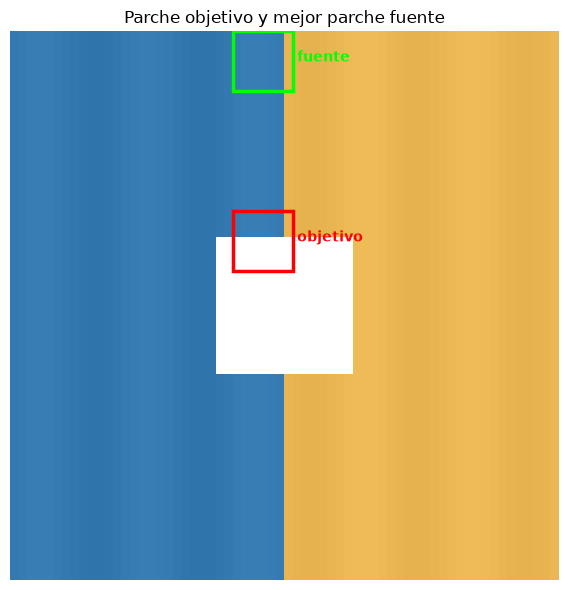

In [5]:
comparacion = e._imagen_comparacion(danada)  # Representación interna para SSD (Lab)
fuente, ssd = e.buscar_parche_fuente(comparacion, mascara, mascara, elegido, tam_parche)
print("Centro objetivo:", elegido, "| centro fuente:", fuente)
print(f"SSD sobre los píxeles conocidos: {ssd:.2f}")

# Verificación: el parche fuente NO contiene ningún píxel originalmente dañado.
r = tam_parche // 2
f, c = fuente
assert not mascara[f-r:f+r+1, c-r:c+r+1].any()

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(danada)
for centro, color, texto in ((elegido, "red", "objetivo"), (fuente, "lime", "fuente")):
    f,c = centro
    ax.add_patch(Rectangle((c-r-.5,f-r-.5), tam_parche, tam_parche,
                           fill=False, edgecolor=color, linewidth=2.5))
    ax.text(c+r+1, f, texto, color=color, fontsize=10, weight="bold")
ax.axis("off"); ax.set_title("Parche objetivo y mejor parche fuente")
plt.tight_layout(); plt.show()

## 5. Una sola iteración por dentro

Llamamos `inpainting_ejemplares(..., max_iteraciones=1, devolver_historial=True)`. **Una iteración es un parche objetivo seleccionado y rellenado, no un píxel individual**.

En el registro de la iteración guardamos la imagen antes/después, la frontera, las prioridades, el parche elegido, cuántos píxeles se han copiado y cuánto hueco queda. Estos estados son opcionales para no consumir memoria en la ejecución normal.

Iteración 1: objetivo (24, 29) → fuente (3, 29)
P=0.0635  SSD=0.00  nuevos=28  restantes=228


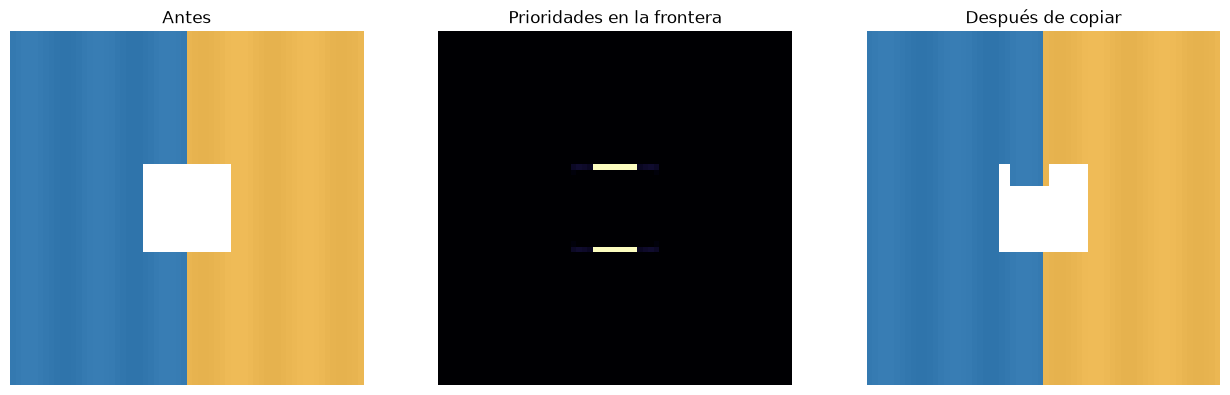

In [6]:
parcial, usadas, historial = e.inpainting_ejemplares(
    danada, mascara, tam_parche=tam_parche,
    max_iteraciones=1, devolver_historial=True, guardar_primeras=1
)
paso = historial[0]
assert usadas == 1
assert paso["nuevos"] == int(mascara.sum() - paso["restantes"])
assert np.array_equal(parcial[~mascara], original[~mascara])
print(f"Iteración {paso['iteracion']}: objetivo {paso['centro_objetivo']} → fuente {paso['centro_fuente']}")
print(f"P={paso['P']:.4f}  SSD={paso['ssd']:.2f}  nuevos={paso['nuevos']}  restantes={paso['restantes']}")

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
axes[0].imshow(paso["imagen_antes"]); axes[0].set_title("Antes")
axes[1].imshow(paso["prioridades"], cmap="magma"); axes[1].set_title("Prioridades en la frontera")
axes[2].imshow(paso["imagen_despues"]); axes[2].set_title("Después de copiar")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

## 6. Reconstrucción completa: de la frontera hacia dentro

La función principal repite [1, tabla I]: calcular la prioridad del borde, elegir el mayor valor, buscar el parche fuente, copiar solo lo desconocido y actualizar confianza y máscara. Para un hueco pequeño podemos mostrar las primeras iteraciones y el resultado final.

Comprobamos dos propiedades fundamentales: **no se modifica ningún píxel conocido originalmente** y **la máscara termina vacía** (las iteraciones van copiando píxeles nuevos). La función devuelve `(restaurada, numero_iteraciones)`; si pedimos historial devuelve una tercera componente.

Iteraciones (parches): 16 | tiempo: 0.086 s
MSE en el hueco: 0.00
PSNR en el hueco: inf dB


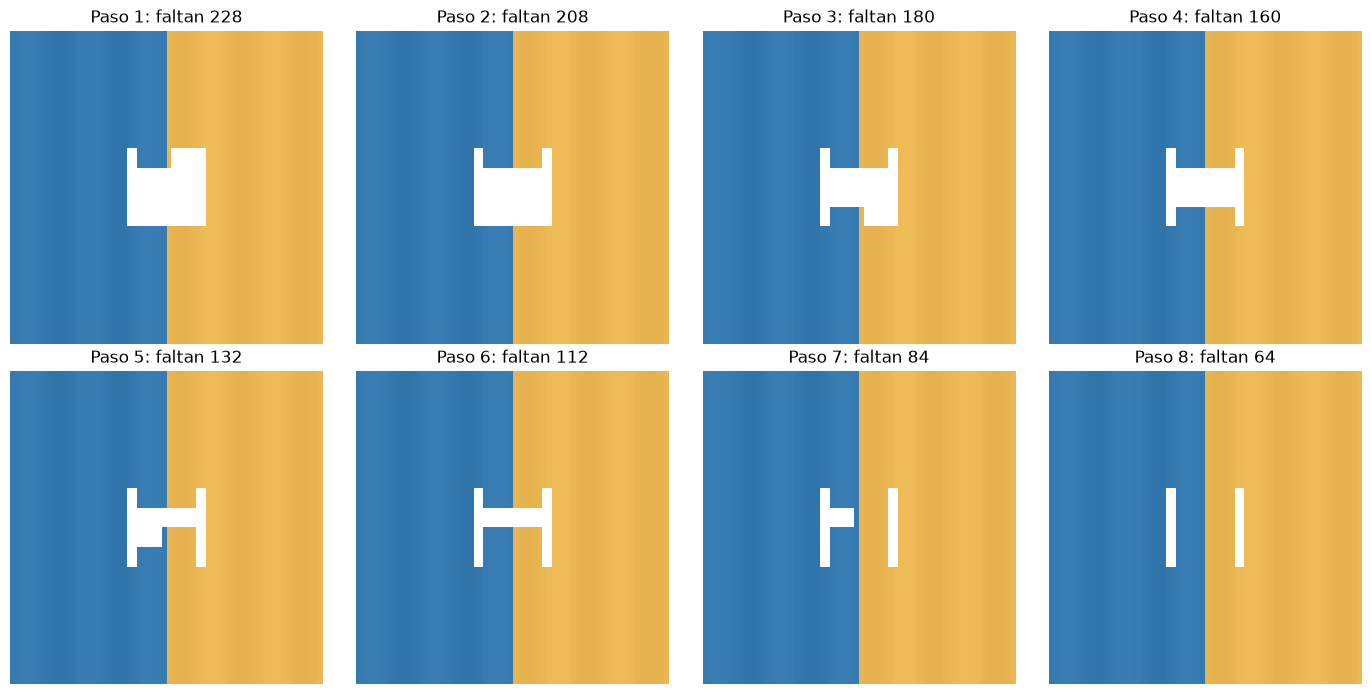

In [7]:
inicio = time.perf_counter()
restaurada, iteraciones, historial = e.inpainting_ejemplares(
    danada, mascara, tam_parche=tam_parche, devolver_historial=True,
    guardar_primeras=8
)
segundos = time.perf_counter() - inicio
assert np.array_equal(restaurada[~mascara], original[~mascara])
assert restaurada.shape == original.shape and restaurada.dtype == original.dtype
assert historial[-1]["restantes"] < mascara.sum()
print(f"Iteraciones (parches): {iteraciones} | tiempo: {segundos:.3f} s")
print("MSE en el hueco:", f"{k.mse(original, restaurada, mascara):.2f}")
print("PSNR en el hueco:", f"{k.psnr(original, restaurada, mascara):.2f} dB")

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for i, ax in enumerate(axes.flat):
    if i < len(historial):
        estado = historial[i]
        ax.imshow(estado["imagen_despues"])
        ax.set_title(f"Paso {estado['iteracion']}: faltan {estado['restantes']}")
    else:
        ax.imshow(restaurada)
        ax.set_title("Resultado final")
    ax.axis("off")
plt.tight_layout(); plt.show()

## 7. Evaluación sobre la misma fotografía de Juanlu

En `01_mascaras.ipynb`, `02_metricas.ipynb`, `03_difusion_simple.ipynb` y `04_bertalmio.ipynb`, Juanlu utiliza `photo-1431315906474-0e7a186c0304.jpg`, que ya está en `images/originales/` del repositorio. **No hace falta añadir otra imagen.** Para que la búsqueda exhaustiva sea manejable, la reducimos a 96 píxeles de ancho y creamos una máscara cuadrada pequeña mediante su `mascaras.py`.

Si ejecutas una copia del notebook fuera del repositorio o sin las fotos, usaremos una imagen sintética como alternativa y el cuaderno lo avisará. Ese resultado no debe confundirse con un experimento sobre una fotografía real.

Fotografía real, misma que usa Juanlu (reducida) | tamaño: (66, 96, 3)


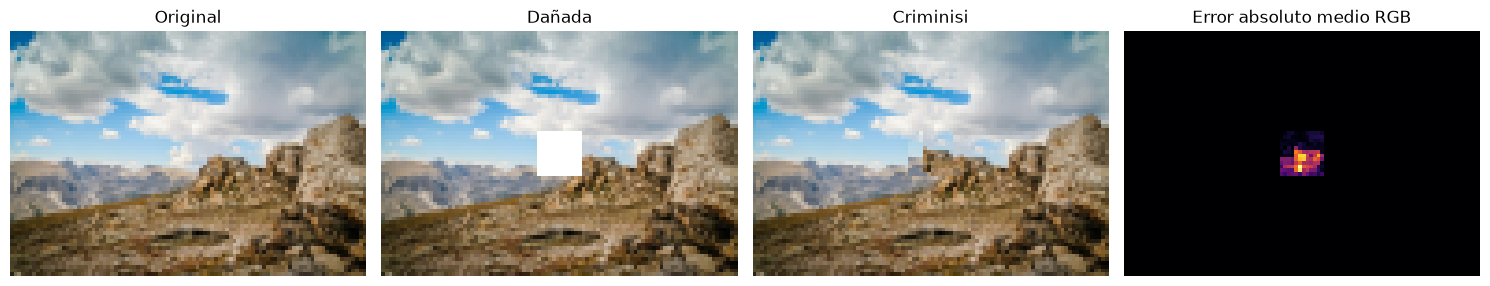

Parches rellenados: 9 | tiempo (una ejecución): 0.037 s
mse_hueco     : 4315.414
psnr_hueco    : 11.781
mse_imagen    : 98.078
psnr_imagen   : 28.215


In [8]:
ruta_foto = raiz / "images" / "originales" / "photo-1431315906474-0e7a186c0304.jpg"
if ruta_foto.is_file():
    foto_bgr = cv.imread(str(ruta_foto))
    if foto_bgr is None:
        raise RuntimeError(f"No se ha podido leer {ruta_foto}")
    foto = cv.cvtColor(foto_bgr, cv.COLOR_BGR2RGB)
    ancho = 96
    alto = max(32, round(foto.shape[0] * ancho / foto.shape[1]))
    foto = cv.resize(foto, (ancho, alto), interpolation=cv.INTER_AREA)
    origen_foto = "Fotografía real, misma que usa Juanlu (reducida)"
else:
    # Recurso de emergencia para ejecutar el notebook sin la carpeta images/.
    foto = original.copy()
    origen_foto = "IMAGEN SINTÉTICA: no se encontró la fotografía del repositorio"
    print("AVISO:", origen_foto)

mascara_foto = m.mascara_cuadrada(foto.shape[:2], lado=12)
danada_foto = m.aplicar_mascara(foto, mascara_foto)
print(origen_foto, "| tamaño:", foto.shape)

inicio = time.perf_counter()
restaurada_foto, iter_foto = e.inpainting_ejemplares(danada_foto, mascara_foto, tam_parche=7)
tiempo_foto = time.perf_counter() - inicio
resultados = k.evaluar(foto, restaurada_foto, mascara_foto)

fig, axes = plt.subplots(1, 4, figsize=(15, 4))
axes[0].imshow(foto); axes[0].set_title("Original")
axes[1].imshow(danada_foto); axes[1].set_title("Dañada")
axes[2].imshow(restaurada_foto); axes[2].set_title("Criminisi")
error = np.mean(np.abs(foto.astype(float)-restaurada_foto.astype(float)), axis=2)
axes[3].imshow(error, cmap="inferno"); axes[3].set_title("Error absoluto medio RGB")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

print("Parches rellenados:", iter_foto, "| tiempo (una ejecución):", f"{tiempo_foto:.3f} s")
for nombre, valor in resultados.items():
    print(f"{nombre:14s}: {valor:.3f}")

## 8. El tamaño del parche importa

Criminisi sugiere una ventana por defecto de **9×9**, ligeramente mayor que el elemento de textura que queramos reconstruir [1, sección III]. Comparamos 5×5, 7×7 y 9×9 **sobre la misma imagen sintética y la misma máscara**, evitando cambiar dos variables a la vez.

Este experimento es **exploratorio**: una sola imagen no permite concluir cuál tamaño es mejor en general. Tampoco deben compararse tiempos medidos aquí con los de Juanlu en otro ordenador; para la fase 3 ejecutaremos todos los métodos en una misma máquina.

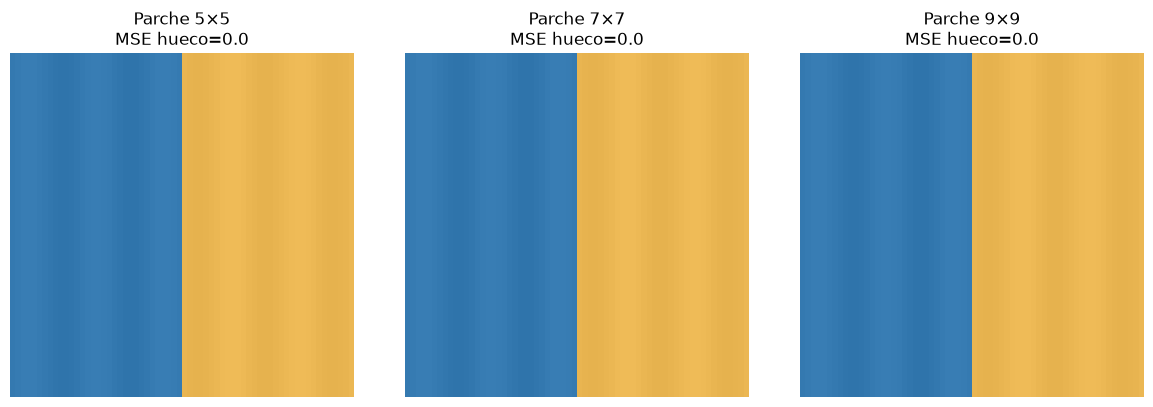

Tamaño | Parches usados | MSE hueco | Tiempo (s)
     5 |            28 |      0.00 |     0.077
     7 |            16 |      0.00 |     0.031
     9 |            12 |      0.00 |     0.030


In [9]:
resultados_parches = []
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, tam in zip(axes, (5, 7, 9)):
    t0 = time.perf_counter()
    salida, n = e.inpainting_ejemplares(danada, mascara, tam_parche=tam)
    segundos = time.perf_counter() - t0
    error = k.mse(original, salida, mascara)
    resultados_parches.append((tam, n, error, segundos))
    ax.imshow(salida)
    ax.set_title(f"Parche {tam}×{tam}\nMSE hueco={error:.1f}")
    ax.axis("off")
plt.tight_layout(); plt.show()
print("Tamaño | Parches usados | MSE hueco | Tiempo (s)")
for tam, n, err, t in resultados_parches:
    print(f"{tam:>6} | {n:>13} | {err:>9.2f} | {t:>9.3f}")

## 9. Comprobaciones de robustez

Además de las figuras, probamos casos donde un error de implementación se detecta fácilmente:

1. **Imagen uniforme**: un hueco debe recuperar exactamente el mismo color. Como no hay bordes, todos los términos de datos pueden dar cero y usamos la confianza para desempatar.
2. **Hueco al borde físico de la foto**: la ventana objetivo se recorta de forma coherente y la búsqueda utiliza una ventana fuente completa.
3. **Sin hueco**: se devuelve una copia sin iteraciones.
4. **No tocar los conocidos**: comprobación exacta con `np.array_equal`.
5. **Sin fuente válida**: se informa mediante `ValueError` en lugar de inventar un parche.

Las dos últimas comprobaciones son especialmente útiles para la evaluación del algoritmo sobre diferentes máscaras.

In [ ]:
plana = np.full((26, 30, 3), [80, 110, 140], dtype=np.uint8)
h = np.zeros(plana.shape[:2], dtype=bool)
h[10:16, 12:18] = True
plana_danada = m.aplicar_mascara(plana, h)
plana_out, n = e.inpainting_ejemplares(plana_danada, h, tam_parche=5)
assert np.array_equal(plana_out, plana)
assert n > 0

borde_img = np.full((24, 24), 133, dtype=np.uint8)
borde_mask = np.zeros((24,24), dtype=bool)
borde_mask[:5, :5] = True
borde_danada = borde_img.copy(); borde_danada[borde_mask] = 255
borde_out, _ = e.inpainting_ejemplares(borde_danada, borde_mask, tam_parche=5)
assert np.array_equal(borde_out, borde_img)

sin_hueco = np.zeros((24,24), dtype=bool)
copia, n = e.inpainting_ejemplares(borde_img, sin_hueco, tam_parche=5)
assert n == 0 and np.array_equal(copia, borde_img) and not np.shares_memory(copia, borde_img)

try:
    sin_fuentes = np.ones((12,12), dtype=bool)
    sin_fuentes[0,0] = False
    e.inpainting_ejemplares(np.zeros((12,12), dtype=np.uint8), sin_fuentes, tam_parche=5)
    raise AssertionError("Se esperaba ValueError al no haber ningún parche fuente válido")
except ValueError:
    pass

print("OK: imagen plana, hueco en esquina, sin hueco, entrada intacta y error sin fuentes")

## 10. Decisiones de diseño, limitaciones y trabajo pendiente

| Componente | Qué indica Criminisi [1] | Cómo lo hemos concretado |
|---|---|---|
| Prioridad | $P(p)=C(p)D(p)$, sec. III, ec. (1) | Exactamente este producto; desempate por confianza y orden de lectura si hay igualdad |
| Confianza | Media de valores conocidos dentro del parche | Se actualiza únicamente en píxeles recién copiados; en bordes físicos se usa el área recortada |
| Término de datos | Isófota y normal a la frontera | Normal del gradiente de máscara suavizada; gradiente máximo entre píxeles conocidos con diferencias centrales/unilaterales |
| Fuente $\Phi$ | Región fuente fija, sec. II.A y III | Parches completos procedentes **solo de la región originalmente conocida** |
| Búsqueda | Parche más parecido por SSD, sec. III, ec. (2) | Exhaustiva por lotes; en gris intensidad y en RGB CIE Lab |
| Copia | Solo posiciones desconocidas | Se conserva la imagen y confianza de los píxeles ya conocidos |
| Orden de reconstrucción | Mejor prioridad en cada paso | Se recalculan borde, confianza y datos tras cada copia |

**Limitaciones conocidas.** La búsqueda exhaustiva puede ser lenta en fotos grandes; el método necesita texturas similares disponibles en $\Phi$; un parche mal elegido puede contaminar iteraciones posteriores; la calidad cambia con el tamaño del parche. La segmentación de objetos y el entrenamiento de redes neuronales **no forman parte** de esta implementación.

**Fase 3:** comparar con difusión simple y Bertalmio sobre varias imágenes y máscaras idénticas, midiendo MSE y PSNR *sobre el hueco*, tiempos en un mismo equipo y diferencias visuales. También se podría estudiar PatchMatch para acelerar la búsqueda, pero no hace falta para el producto mínimo viable.

**Uso de IA:** el diseño de este módulo y cuaderno recibió ayuda de ChatGPT. Hay que declararlo en el apartado de uso de IA de la memoria, citar el artículo original, revisar el código, ejecutar las pruebas y justificar las decisiones de discretización. Los resultados del cuaderno son producidos por el código, no por generación de imágenes.

### Resumen

El algoritmo reconstruye un hueco **parche a parche**; la prioridad define **dónde** rellenar y la SSD determina **qué contenido copiar**. El método no necesita entrenar un modelo, pero depende de que haya ejemplares adecuados en la región fuente original.